# Shortest-Path Algorithms on a Campus Pedestrian Graph — Final Analysis Notebook

**Sabaragamuwa University of Sri Lanka — Campus Navigator experiment**

**Research Questions:**
- **RQ1:** How do the route distances returned by Dijkstra’s algorithm, A∗ and BFS compare on the campus network?
- **RQ2:** How do the execution times and the numbers of expanded nodes of the three algorithms diﬀer across matched origin–destination pairs?
- **RQ3:** How often do the algorithms return different paths, and how does the topology of the campus graph constrain such diﬀerences?
- **RQ4:** How do the distances of application generated routes compare with independently measured distances for selected campus journeys?

The automated benchmark and the three manually recorded journeys are analyzed separately. The physical journeys are a small descriptive case study, not a general accuracy validation.

In [ ]:
import os, math, time, random, heapq, hashlib, zipfile, json, gc, warnings
import xml.etree.ElementTree as ET
from collections import deque

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy import stats
from IPython.display import display

from build_graph import build_campus_graph

# ---------------- configuration ----------------
RANDOM_SEED     = 42
N_PAIRS         = 100            # uniform random node pairs
N_NAMED_PAIRS   = 100            # pairs between named KMZ locations
TIMING_REPEATS  = 10
KMZ_PATH        = 'SABRA.kmz-2'  # same file name you passed to build_campus_graph before
PHYS_CSV        = 'physical_journeys.csv'   # optional, see Section 9
OUT_DIR, FIG_DIR = 'outputs', 'figures'
TOL = 1e-6                       # metres; tolerance for "equal distance"

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
warnings.filterwarnings('ignore')

ALGOS = ['Dijkstra', 'A*', 'BFS']
SHORT = {'Dijkstra': 'Dij', 'A*': 'Ast', 'BFS': 'Bfs'}
COL   = {'Dijkstra': '#2c4a3b', 'A*': '#6b8f71', 'BFS': '#c96a4e'}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 12, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

# ---------------- LaTeX macro store ----------------
NUM = {}
def put(name, value):
    """Store a value as the LaTeX macro \\<name>. Names must contain letters only."""
    assert name.isalpha(), name
    NUM[name] = str(value)

def f0(x):  return f"{x:,.0f}"
def f1(x):  return f"{x:,.1f}".replace('-', '$-$')
def f2(x):  return f"{x:,.2f}".replace('-', '$-$')
def f4(x):  return f"{x:,.4f}".replace('-', '$-$')
def ptex(p):
    return '$p<0.001$' if p < 0.001 else f'$p={p:.3f}$'

def savefig(name):
    plt.savefig(f'{FIG_DIR}/{name}.pdf', bbox_inches='tight')
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=300, bbox_inches='tight')

put('RSeed', RANDOM_SEED); put('RPairs', N_PAIRS); put('RRepeats', TIMING_REPEATS)
print('Configuration loaded.')

Configuration loaded.


## 1 — Load the graph and record provenance

In [45]:
campus_graph = build_campus_graph(KMZ_PATH)
G = campus_graph

kmz_sha = None
if os.path.exists(KMZ_PATH):
    with open(KMZ_PATH, 'rb') as fh:
        kmz_sha = hashlib.sha256(fh.read()).hexdigest()

print(f'Nodes: {G.number_of_nodes():,}   Edges: {G.number_of_edges():,}   '
      f'Components: {nx.number_connected_components(G)}')
print('KMZ SHA-256:', kmz_sha)
assert isinstance(G, nx.Graph) and not G.is_directed() and not G.is_multigraph(), 'Expected a simple undirected nx.Graph'

Nodes: 1,953   Edges: 1,977   Components: 2
KMZ SHA-256: bea61e136c05cf6437c3c99b7f9ed53aaf74f7b2a4aed7f7ecb1aa1cb62b172e


## 2 — Helper functions

In [46]:
R_EARTH = 6_371_000.0

def haversine(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres (R = 6,371,000 m)."""
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dphi, dlam = math.radians(lat2 - lat1), math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dlam / 2) ** 2
    return 2 * R_EARTH * math.asin(math.sqrt(a))     # same form as Eq. in the paper

def astar_heuristic(u, v):
    return haversine(u[0], u[1], v[0], v[1])

def path_distance(graph, path):
    return sum(graph[path[i]][path[i + 1]]['weight'] for i in range(len(path) - 1))

def tex_escape(s):
    return (str(s).replace('\\', ' ').replace('&', '\\&').replace('%', '\\%')
            .replace('_', '\\_').replace('#', '\\#').replace('→', '--').replace('–', '--'))
print('Helpers defined.')

Helpers defined.


## 3 — Graph diagnostics and topology

* Connected components and their sizes.
* Edge-weight sanity checks. Because every weight equals the endpoint Haversine distance, the A\* heuristic is admissible and consistent.
* **Cyclomatic number** \(E - V + C\): the number of independent cycles (loops). Here it is small, so the graph is *sparse*,
  but the loops are long (many densified edges each), so most edges still lie on a cycle.
* **Bridges**: an edge whose removal disconnects the graph. A route that uses only bridge edges has exactly one simple path, so algorithms cannot disagree on it;
  only routes that use at least one non-bridge (cycle) edge can differ between algorithms. The notebook checks this empirically.

In [47]:
components = sorted(nx.connected_components(G), key=len, reverse=True)
comp_of = {n: i for i, c in enumerate(components) for n in c}
comp_table = pd.DataFrame({
    'component_rank': range(1, len(components) + 1),
    'nodes': [len(c) for c in components],
    'edges': [G.subgraph(c).number_of_edges() for c in components],
})
display(comp_table)

w = np.array([d['weight'] for _, _, d in G.edges(data=True)], dtype=float)
missing = sum(1 for _, _, d in G.edges(data=True) if 'weight' not in d)
w_err = max(abs(d['weight'] - haversine(u[0], u[1], v[0], v[1])) for u, v, d in G.edges(data=True))
print(f'Edges missing weight: {missing} | non-positive weights: {(w <= 0).sum()}')
print(f'Edge length min/median/max: {w.min():.2f} / {np.median(w):.2f} / {w.max():.2f} m')
print(f'Max |stored weight - endpoint Haversine|: {w_err:.2e} m  -> heuristic admissible & consistent: {w_err < 1e-6}')
assert missing == 0 and (w > 0).all()

V, E, C = G.number_of_nodes(), G.number_of_edges(), len(components)
n_cycles = E - V + C
bridge_set = {frozenset(e) for e in nx.bridges(G)}
n_bridges = len(bridge_set)
print(f'Cyclomatic number (independent cycles): {n_cycles}')
print(f'Bridges: {n_bridges} of {E} edges ({100*n_bridges/E:.1f}%)')

put('RNodes', f0(V)); put('REdges', f0(E)); put('RComps', C)
put('RCompMain', f0(len(components[0]))); put('RCompSmall', f0(len(components[-1])))
put('RCycles', n_cycles); put('RBridges', f0(n_bridges)); put('RBridgePct', f1(100 * n_bridges / E))
put('RNonBridgePct', f1(100 - 100 * n_bridges / E))
put('RWMin', f2(w.min())); put('RWMed', f2(np.median(w))); put('RWMax', f2(w.max()))
put('RWDiff', f'{w_err:.1e}')

,component_rank,nodes,edges
0,1,1947,1972
1,2,6,5


Edges missing weight: 0 | non-positive weights: 0
Edge length min/median/max: 1.20 / 5.18 / 9.85 m
Max |stored weight - endpoint Haversine|: 1.78e-15 m  -> heuristic admissible & consistent: True
Cyclomatic number (independent cycles): 26
Bridges: 338 of 1977 edges (17.1%)


## 4 — Algorithm implementations (single-direction) and cross-checks

All three stop as soon as the target is removed from the queue (A\*, Dijkstra) or discovered (BFS: stop when popped, for a uniform count).
`nodes_expanded` counts nodes removed from the open set and expanded.

In [48]:
def _rebuild(parent, t):
    path = []
    while t is not None:
        path.append(t)
        t = parent[t]
    return path[::-1]

def dijkstra_counted(G, s, t):
    dist, parent, done = {s: 0.0}, {s: None}, set()
    pq, expanded = [(0.0, s)], 0
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u); expanded += 1
        if u == t:
            break
        for v, data in G[u].items():
            nd = d + data['weight']
            if nd < dist.get(v, float('inf')):
                dist[v], parent[v] = nd, u
                heapq.heappush(pq, (nd, v))
    return _rebuild(parent, t), expanded

def astar_counted(G, s, t):
    g, parent, done = {s: 0.0}, {s: None}, set()
    pq, expanded = [(astar_heuristic(s, t), s)], 0
    while pq:
        _, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u); expanded += 1
        if u == t:
            break
        for v, data in G[u].items():
            ng = g[u] + data['weight']
            if ng < g.get(v, float('inf')):
                g[v], parent[v] = ng, u
                heapq.heappush(pq, (ng + astar_heuristic(v, t), v))
    return _rebuild(parent, t), expanded

def bfs_counted(G, s, t):
    parent, q, expanded = {s: None}, deque([s]), 0
    while q:
        u = q.popleft(); expanded += 1
        if u == t:
            break
        for v in G[u]:
            if v not in parent:
                parent[v] = u
                q.append(v)
    return _rebuild(parent, t), expanded

def run_algo(algo, G, s, t):
    if algo == 'Dijkstra': return dijkstra_counted(G, s, t)
    if algo == 'A*':       return astar_counted(G, s, t)
    if algo == 'BFS':      return bfs_counted(G, s, t)
    raise ValueError(algo)

# quick self-test on one pair
_s, _t = next(iter(G.nodes())), list(components[0])[-1]
for a in ALGOS:
    p, e = run_algo(a, G, _s, _t)
    print(f'{a:9s} nodes={len(p):4d} expanded={e:5d} dist={path_distance(G, p):9.3f} m')
print('NetworkX reference dist:', round(nx.dijkstra_path_length(G, _s, _t, weight='weight'), 3))

Dijkstra  nodes= 122 expanded= 1083 dist=  652.336 m
A*        nodes= 122 expanded=  472 dist=  652.336 m
BFS       nodes= 122 expanded= 1051 dist=  652.336 m
NetworkX reference dist: 652.336


## 5 — Benchmark function

For every pair: all three algorithms are run and **validated** against NetworkX
(Dijkstra and A\* distance = `nx.dijkstra_path_length`; BFS hop count = `nx.shortest_path_length`).
Then one warm-up round, followed by `TIMING_REPEATS` timed rounds with the algorithm order shuffled in every round and garbage collection disabled.
The **median** of the repeats is stored. The pair sampler and the timing shuffler use *separate* random generators, so the pair list depends only on the seed.

> The pairs are therefore not identical to those of the earlier run (the old sampler shared one generator with the timing shuffle).
> Numbers change slightly; that is expected, and the paper must use only this run.

In [49]:
def sample_pairs_uniform(G, n, seed):
    rng = random.Random(seed)
    nodes = sorted(G.nodes())      # sorted -> pair list does not depend on node insertion order
    pairs, attempts = [], 0
    while len(pairs) < n and attempts < n * 1000:
        attempts += 1
        s, t = rng.sample(nodes, 2)
        if comp_of[s] == comp_of[t]:
            pairs.append((s, t))
    if len(pairs) < n:
        raise RuntimeError('Could not find enough connected pairs.')
    return pairs, attempts

def benchmark(G, pairs, repeats=10, seed=42, label=''):
    rng = random.Random(seed + 1)
    records = []
    for rid, (s, t) in enumerate(pairs):
        res = {a: run_algo(a, G, s, t) for a in ALGOS}

        # ---- correctness validation against NetworkX ----
        ref = nx.dijkstra_path_length(G, s, t, weight='weight')
        d_dij = path_distance(G, res['Dijkstra'][0])
        d_ast = path_distance(G, res['A*'][0])
        hops_ref = nx.shortest_path_length(G, s, t)
        if abs(d_dij - ref) > TOL or abs(d_ast - ref) > TOL or (len(res['BFS'][0]) - 1) != hops_ref:
            raise AssertionError(f'Validation failed on pair {rid}: {d_dij}, {d_ast}, {ref}')

        # ---- warm-up (order shuffled) ----
        for a in rng.sample(ALGOS, len(ALGOS)):
            run_algo(a, G, s, t)

        # ---- timed repeats ----
        times = {a: [] for a in ALGOS}
        gc.collect(); gc.disable()
        try:
            for _ in range(repeats):
                order = ALGOS[:]
                rng.shuffle(order)
                for a in order:
                    t0 = time.perf_counter_ns()
                    run_algo(a, G, s, t)
                    t1 = time.perf_counter_ns()
                    times[a].append((t1 - t0) / 1e6)
        finally:
            gc.enable()

        straight = haversine(s[0], s[1], t[0], t[1])
        for a in ALGOS:
            path, expanded = res[a]
            records.append({
                'route_id': rid, 'start_node': s, 'end_node': t, 'algorithm': a,
                'execution_time_ms': float(np.median(times[a])),
                'distance': path_distance(G, path),
                'node_count': len(path), 'hops': len(path) - 1,
                'nodes_expanded': expanded, 'straight_line_m': straight,
                'path_nodes': path,
            })
        if (rid + 1) % 20 == 0:
            print(f'  [{label}] {rid + 1}/{len(pairs)} pairs done')
    return pd.DataFrame(records)

print('Benchmark function defined.')

Benchmark function defined.


## 6 — Run the uniform-random benchmark

In [50]:
pairs_uniform, attempts = sample_pairs_uniform(G, N_PAIRS, RANDOM_SEED)
print(f'{len(pairs_uniform)} connected pairs found in {attempts} attempts')
df = benchmark(G, pairs_uniform, repeats=TIMING_REPEATS, seed=RANDOM_SEED, label='uniform')
put('RAttempts', attempts); put('RValidated', len(pairs_uniform))

summary = (df.groupby('algorithm')[['execution_time_ms', 'nodes_expanded', 'distance', 'node_count']]
             .agg(['mean', 'median', 'std', 'min', 'max']).loc[ALGOS].round(4))
display(summary)

mean_t = df.groupby('algorithm')['execution_time_ms'].mean()
med_t  = df.groupby('algorithm')['execution_time_ms'].median()
mean_e = df.groupby('algorithm')['nodes_expanded'].mean()
med_e  = df.groupby('algorithm')['nodes_expanded'].median()
mean_d = df.groupby('algorithm')['distance'].mean()
med_d  = df.groupby('algorithm')['distance'].median()
mean_n = df.groupby('algorithm')['node_count'].mean()
med_n  = df.groupby('algorithm')['node_count'].median()
for a in ALGOS:
    k = SHORT[a]
    put(f'RTimeMean{k}', f4(mean_t[a])); put(f'RTimeMed{k}', f4(med_t[a]))
    put(f'RExpMean{k}', f1(mean_e[a]));  put(f'RExpMed{k}', f1(med_e[a]))
    put(f'RDistMean{k}', f2(mean_d[a])); put(f'RDistMed{k}', f2(med_d[a]))
    put(f'RNodesMean{k}', f2(mean_n[a])); put(f'RNodesMed{k}', f1(med_n[a]))
put('RDistMin', f2(df['distance'].min())); put('RDistMax', f2(df['distance'].max()))
put('RTimeImprov', f1(100 * (mean_t['Dijkstra'] - mean_t['A*']) / mean_t['Dijkstra']))
put('RExpImprov',  f1(100 * (mean_e['Dijkstra'] - mean_e['A*']) / mean_e['Dijkstra']))

100 connected pairs found in 102 attempts
  [uniform] 20/100 pairs done
  [uniform] 40/100 pairs done
  [uniform] 60/100 pairs done
  [uniform] 80/100 pairs done
  [uniform] 100/100 pairs done


execution_time_ms                                 nodes_expanded  \
                       mean  median     std     min     max           mean   
algorithm                                                                    
Dijkstra             1.4671  1.4388  0.7975  0.0259  2.9635         999.00   
A*                   1.0377  0.7829  0.9407  0.0297  4.3282         451.64   
BFS                  0.5471  0.5384  0.2989  0.0105  1.1173         998.50   

                                      distance                              \
          median       std min   max      mean   median       std      min   
algorithm                                                                    
Dijkstra   994.5  532.6978  20  1935  860.1180  774.294  506.6322  56.3116   
A*         342.5  403.5285  12  1880  860.1180  774.294  506.6322  56.3116   
BFS        982.0  535.1819  20  1935  861.2448  774.294  507.3563  56.3116   

                     node_count                           
                 max       mean median      std min  max  
algorithm                                                 
Dijkstra   2010.5167     164.27  147.0  97.5083  12  389  
A*         2010.5167     164.27  147.0  97.5083  12  389  
BFS        2013.9600     164.13  147.0  97.3950  12  389

## 7 — Statistical helpers (paired analysis on matched routes)

In [51]:
def holm(p):
    p = np.asarray(p, float); m = len(p); order = np.argsort(p)
    adj = np.empty(m); run = 0.0
    for rank, idx in enumerate(order):
        run = max(run, (m - rank) * p[idx]); adj[idx] = min(run, 1.0)
    return adj

def paired_stats(a, b, n_boot=10000, seed=42):
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = a - b
    rng = np.random.default_rng(seed)
    boots = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(axis=1)
    lo, hi = np.quantile(boots, [0.025, 0.975])
    nonzero = ~np.isclose(d, 0, atol=TOL)
    if nonzero.sum() == 0:
        t_p = w_p = 1.0
    else:
        t_p = float(stats.ttest_rel(a, b).pvalue)
        try:
            w_p = float(stats.wilcoxon(d, zero_method='wilcox').pvalue)
        except ValueError:
            w_p = 1.0
    sd = d.std(ddof=1)
    return {'n': len(d), 'mean_diff': d.mean(), 'median_diff': float(np.median(d)),
            'ci_lo': lo, 'ci_hi': hi, 'paired_t_p': t_p, 'wilcoxon_p': w_p,
            'dz': (d.mean() / sd) if sd > 0 else 0.0,
            'first_larger': int((d > TOL).sum()), 'second_larger': int((d < -TOL).sum()),
            'ties': int((~nonzero).sum())}

COMPARISONS = [('A*', 'Dijkstra'), ('BFS', 'Dijkstra'), ('BFS', 'A*')]
CODE = {('A*', 'Dijkstra'): 'AD', ('BFS', 'Dijkstra'): 'BD', ('BFS', 'A*'): 'BA'}

def wide(d, col):
    return d.pivot(index='route_id', columns='algorithm', values=col)[ALGOS]

def paired_table(d, metric):
    W = wide(d, metric)
    rows = []
    for a, b in COMPARISONS:
        s = paired_stats(W[a].values, W[b].values, seed=RANDOM_SEED)
        s.update({'metric': metric, 'comparison': f'{a} - {b}'})
        rows.append(s)
    out = pd.DataFrame(rows)
    out['wilcoxon_p_holm'] = holm(out['wilcoxon_p'].values)
    return out

print('Statistical helpers defined.')

Statistical helpers defined.


## 8 — RQ1: route distance (matched pairs)

Dijkstra and A\* should return the same distance (theory + verified admissible heuristic) — this is a **correctness check**, not a finding.
For BFS the quantities of interest are *how often* it is longer and *by how much*.

,n,mean_diff,median_diff,ci_lo,ci_hi,paired_t_p,wilcoxon_p,dz,first_larger,second_larger,ties,metric,comparison,wilcoxon_p_holm
0,100,0.000000,0.0,0.000000,0.000000,1.000000,1.000000,0.000000,0,0,100,distance,A* - Dijkstra,1.000000
1,100,1.126733,0.0,0.446935,2.198159,0.017237,0.000435,0.242238,16,0,84,distance,BFS - Dijkstra,0.001305
2,100,1.126733,0.0,0.446935,2.198159,0.017237,0.000435,0.242238,16,0,84,distance,BFS - A*,0.001305


Dijkstra vs A*: max |difference| = 0.00e+00 m
BFS longer: 16 | equal: 84 | shorter: 0
Mean extra: 1.127 m | median: 0.000 m | max: 43.553 m (3.89%)
Among the 16 longer routes: mean extra 7.04 m, mean overhead 0.63%


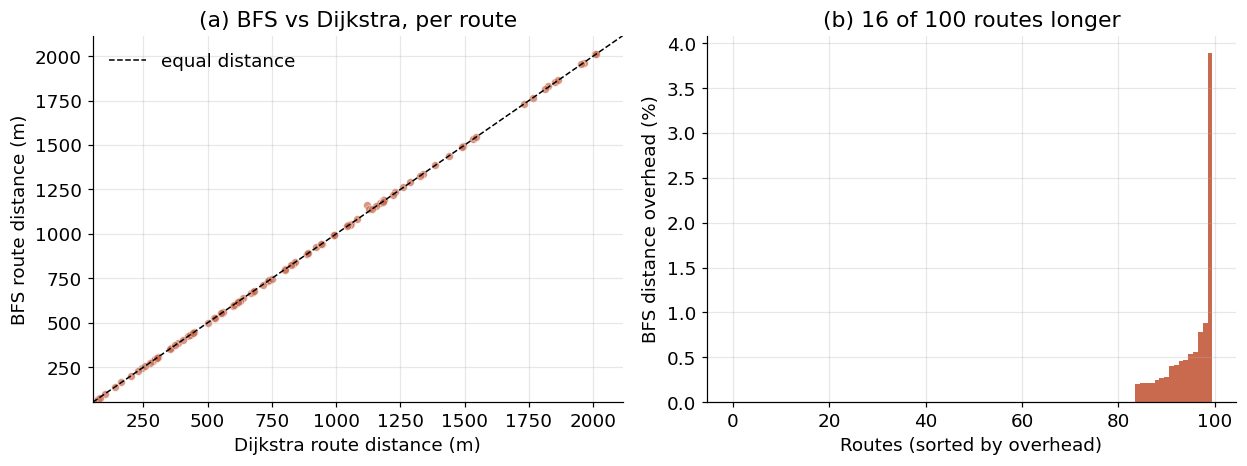

In [52]:
Wd = wide(df, 'distance')
dist_tests = paired_table(df, 'distance')
display(dist_tests.round(6))

max_da = float((Wd['Dijkstra'] - Wd['A*']).abs().max())
over_m   = Wd['BFS'] - Wd['Dijkstra']
over_pct = 100 * over_m / Wd['Dijkstra']
n_longer  = int((over_m >  TOL).sum())
n_equal   = int((over_m.abs() <= TOL).sum())
n_shorter = int((over_m < -TOL).sum())
assert n_shorter == 0, 'BFS shorter than Dijkstra -> implementation error'
print(f'Dijkstra vs A*: max |difference| = {max_da:.2e} m')
print(f'BFS longer: {n_longer} | equal: {n_equal} | shorter: {n_shorter}')
print(f'Mean extra: {over_m.mean():.3f} m | median: {over_m.median():.3f} m | max: {over_m.max():.3f} m ({over_pct.max():.2f}%)')
if n_longer:
    print(f'Among the {n_longer} longer routes: mean extra {over_m[over_m > TOL].mean():.2f} m, '
          f'mean overhead {over_pct[over_m > TOL].mean():.2f}%')

put('RMaxDA', '0' if max_da < 1e-9 else f'{max_da:.1e}')
put('RBfsLonger', n_longer); put('RBfsEqual', n_equal); put('RBfsShorter', n_shorter)
put('ROverMeanM', f2(over_m.mean())); put('ROverMaxM', f2(over_m.max()))
put('ROverMeanPct', f2(over_pct.mean())); put('ROverMaxPct', f2(over_pct.max()))
put('ROverMeanLongerM', f2(over_m[over_m > TOL].mean()) if n_longer else 'n/a')
put('ROverMeanLongerPct', f2(over_pct[over_m > TOL].mean()) if n_longer else 'n/a')
r = dist_tests.set_index('comparison').loc['BFS - Dijkstra']
put('RDistBDMean', f2(r['mean_diff'])); put('RDistBDLo', f2(r['ci_lo'])); put('RDistBDHi', f2(r['ci_hi']))
put('RDistBDP', ptex(r['wilcoxon_p_holm']))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
lim = [min(Wd['Dijkstra'].min(), Wd['BFS'].min()) * 0.95, max(Wd['Dijkstra'].max(), Wd['BFS'].max()) * 1.05]
ax[0].scatter(Wd['Dijkstra'], Wd['BFS'], s=26, alpha=0.7, color=COL['BFS'], edgecolor='white', linewidth=0.4)
ax[0].plot(lim, lim, 'k--', lw=1, label='equal distance')
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel('Dijkstra route distance (m)'); ax[0].set_ylabel('BFS route distance (m)')
ax[0].set_title('(a) BFS vs Dijkstra, per route'); ax[0].legend(loc='upper left')
srt = over_pct.sort_values().values
ax[1].bar(range(len(srt)), srt, width=1.0, color=[COL['BFS'] if v > 1e-6 else '#aaaaaa' for v in srt])
ax[1].set_xlabel('Routes (sorted by overhead)'); ax[1].set_ylabel('BFS distance overhead (%)')
ax[1].set_title(f'(b) {n_longer} of {len(srt)} routes longer')
plt.tight_layout(); savefig('fig_distance'); plt.show()

## 9 — RQ2: execution time and nodes expanded

PAIRED EXECUTION TIME (ms)


,n,mean_diff,median_diff,ci_lo,ci_hi,paired_t_p,wilcoxon_p,dz,first_larger,second_larger,ties,metric,comparison,wilcoxon_p_holm
0,100,-0.42939,-0.44197,-0.52713,-0.32905,0.0,0.0,-0.85052,11,89,0,execution_time_ms,A* - Dijkstra,0.0
1,100,-0.91997,-0.89203,-1.01690,-0.82375,0.0,0.0,-1.84152,0,100,0,execution_time_ms,BFS - Dijkstra,0.0
2,100,-0.49057,-0.26891,-0.63558,-0.36183,0.0,0.0,-0.69329,17,83,0,execution_time_ms,BFS - A*,0.0


PAIRED NODES EXPANDED


,n,mean_diff,median_diff,ci_lo,ci_hi,paired_t_p,wilcoxon_p,dz,first_larger,second_larger,ties,metric,comparison,wilcoxon_p_holm
0,100,-547.36,-582.5,-606.502,-491.860,0.000,0.000,-1.864,0,100,0,nodes_expanded,A* - Dijkstra,0.000
1,100,-0.50,-4.0,-4.990,4.340,0.835,0.147,-0.021,34,57,9,nodes_expanded,BFS - Dijkstra,0.147
2,100,546.86,584.5,490.770,606.552,0.000,0.000,1.835,100,0,0,nodes_expanded,BFS - A*,0.000


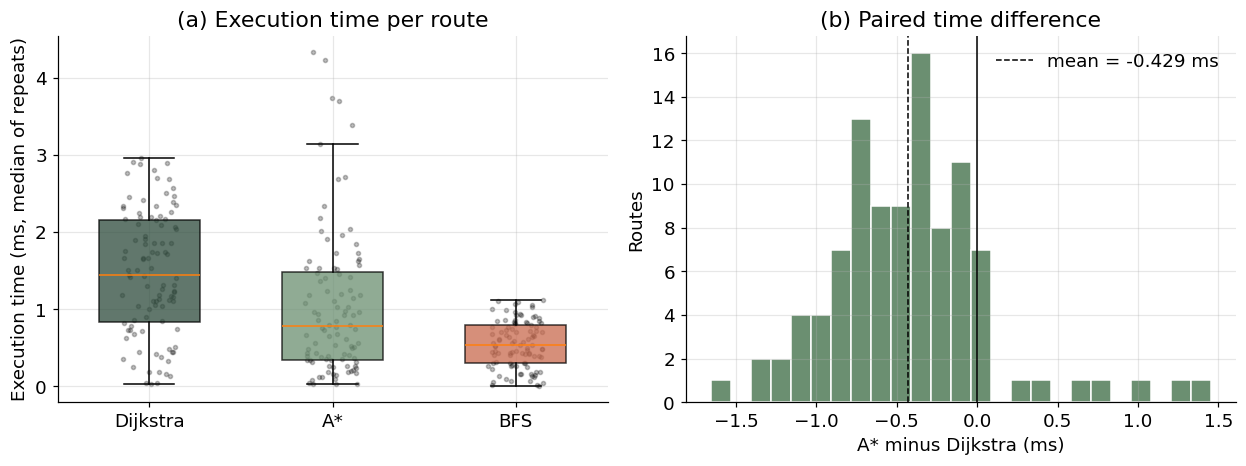

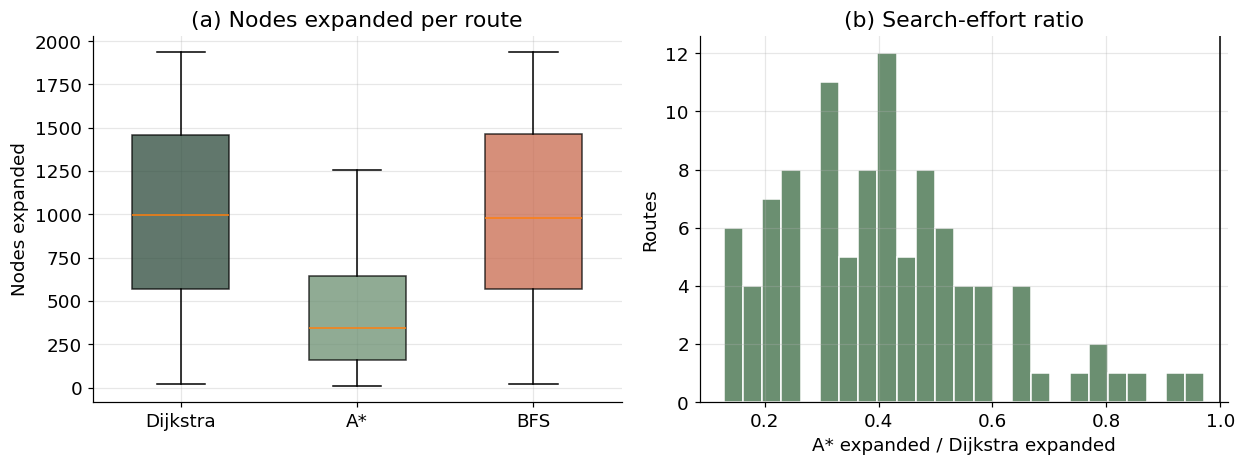

In [53]:
time_tests = paired_table(df, 'execution_time_ms')
exp_tests  = paired_table(df, 'nodes_expanded')
print('PAIRED EXECUTION TIME (ms)'); display(time_tests.round(5))
print('PAIRED NODES EXPANDED');       display(exp_tests.round(3))

tt = time_tests.set_index('comparison'); et = exp_tests.set_index('comparison')
for (a, b), c in CODE.items():
    row = tt.loc[f'{a} - {b}']
    put(f'RTime{c}Mean', f4(row['mean_diff'])); put(f'RTime{c}Lo', f4(row['ci_lo'])); put(f'RTime{c}Hi', f4(row['ci_hi']))
    put(f'RTime{c}P', ptex(row['wilcoxon_p_holm'])); put(f'RTime{c}Fast', int(row['second_larger']))
    row = et.loc[f'{a} - {b}']
    put(f'RExp{c}Mean', f1(row['mean_diff'])); put(f'RExp{c}Lo', f1(row['ci_lo'])); put(f'RExp{c}Hi', f1(row['ci_hi']))
    put(f'RExp{c}P', ptex(row['wilcoxon_p_holm'])); put(f'RExp{c}Fewer', int(row['second_larger']))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
rng_j = np.random.default_rng(0)
data = [df[df.algorithm == a]['execution_time_ms'].values for a in ALGOS]
bp = ax[0].boxplot(data, patch_artist=True, showfliers=False, widths=0.55)
ax[0].set_xticklabels(ALGOS)
for patch, a in zip(bp['boxes'], ALGOS):
    patch.set_facecolor(COL[a]); patch.set_alpha(0.75)
for i, d_ in enumerate(data, start=1):
    ax[0].scatter(i + rng_j.uniform(-0.15, 0.15, len(d_)), d_, s=7, color='k', alpha=0.25)
ax[0].set_ylabel('Execution time (ms, median of repeats)'); ax[0].set_title('(a) Execution time per route')
Wt = wide(df, 'execution_time_ms')
diff = (Wt['A*'] - Wt['Dijkstra']).values
ax[1].hist(diff, bins=25, color=COL['A*'], edgecolor='white')
ax[1].axvline(0, color='k', lw=1); ax[1].axvline(diff.mean(), color='k', ls='--', lw=1, label=f'mean = {diff.mean():.3f} ms')
ax[1].set_xlabel('A* minus Dijkstra (ms)'); ax[1].set_ylabel('Routes'); ax[1].set_title('(b) Paired time difference'); ax[1].legend()
plt.tight_layout(); savefig('fig_time'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4))
data = [df[df.algorithm == a]['nodes_expanded'].values for a in ALGOS]
bp = ax[0].boxplot(data, patch_artist=True, showfliers=False, widths=0.55)
ax[0].set_xticklabels(ALGOS)
for patch, a in zip(bp['boxes'], ALGOS):
    patch.set_facecolor(COL[a]); patch.set_alpha(0.75)
ax[0].set_ylabel('Nodes expanded'); ax[0].set_title('(a) Nodes expanded per route')
We = wide(df, 'nodes_expanded')
ratio = (We['A*'] / We['Dijkstra']).values
ax[1].hist(ratio, bins=25, color=COL['A*'], edgecolor='white')
ax[1].axvline(1, color='k', lw=1)
ax[1].set_xlabel('A* expanded / Dijkstra expanded'); ax[1].set_ylabel('Routes'); ax[1].set_title('(b) Search-effort ratio')
plt.tight_layout(); savefig('fig_expanded'); plt.show()
put('RExpRatioMed', f2(np.median(ratio)))
put('RTimePerExpDij', f4(1000 * mean_t['Dijkstra'] / mean_e['Dijkstra'])); put('RTimePerExpAst', f4(1000 * mean_t['A*'] / mean_e['A*'])); put('RTimePerExpBfs', f4(1000 * mean_t['BFS'] / mean_e['BFS']))

## 10 — RQ3: path agreement and the role of graph topology

,comparison,identical_sequences,mean_edge_jaccard
0,Dijkstra vs A*,100,1.0000
1,Dijkstra vs BFS,84,0.9153
2,A* vs BFS,84,0.9153


Routes that use at least one non-bridge edge: 98 / 100
BFS-longer routes that use a non-bridge edge: 16 / 16
Routes where any algorithm returned a different node sequence: 16; of these on bridge-only routes: 0  (must be 0)


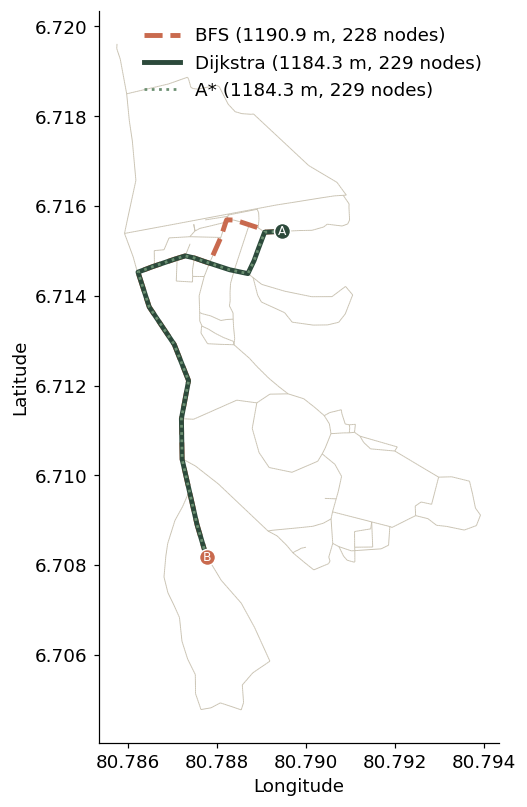

In [54]:
def edge_set(path):
    return {frozenset((path[i], path[i + 1])) for i in range(len(path) - 1)}

def jaccard(a, b):
    u = a | b
    return len(a & b) / len(u) if u else 1.0

def touches_cycle(path):
    """True if the path uses at least one non-bridge edge."""
    return any(frozenset((path[i], path[i + 1])) not in bridge_set for i in range(len(path) - 1))

rows = []
for rid, g in df.groupby('route_id', sort=True):
    p = {r['algorithm']: r['path_nodes'] for _, r in g.iterrows()}
    e = {k: edge_set(v) for k, v in p.items()}
    rows.append({
        'route_id': rid,
        'da_same_seq': p['Dijkstra'] == p['A*'], 'da_same_edges': e['Dijkstra'] == e['A*'],
        'da_jaccard': jaccard(e['Dijkstra'], e['A*']),
        'db_same_seq': p['Dijkstra'] == p['BFS'], 'db_jaccard': jaccard(e['Dijkstra'], e['BFS']),
        'ab_same_seq': p['A*'] == p['BFS'],       'ab_jaccard': jaccard(e['A*'], e['BFS']),
        'touches_cycle': touches_cycle(p['Dijkstra']),
    })
pc = pd.DataFrame(rows).set_index('route_id')
pc['bfs_longer'] = (over_m > TOL).reindex(pc.index)

agree = pd.DataFrame([
    {'comparison': 'Dijkstra vs A*',  'identical_sequences': int(pc.da_same_seq.sum()), 'mean_edge_jaccard': pc.da_jaccard.mean()},
    {'comparison': 'Dijkstra vs BFS', 'identical_sequences': int(pc.db_same_seq.sum()), 'mean_edge_jaccard': pc.db_jaccard.mean()},
    {'comparison': 'A* vs BFS',       'identical_sequences': int(pc.ab_same_seq.sum()), 'mean_edge_jaccard': pc.ab_jaccard.mean()},
])
display(agree.round(4))

n_cyc_routes = int(pc.touches_cycle.sum())
n_longer_cyc = int((pc.bfs_longer & pc.touches_cycle).sum())
n_any_diff   = int((~(pc.da_same_seq & pc.db_same_seq)).sum())
n_diff_nocyc = int((~(pc.da_same_seq & pc.db_same_seq) & ~pc.touches_cycle).sum())
print(f'Routes that use at least one non-bridge edge: {n_cyc_routes} / {len(pc)}')
print(f'BFS-longer routes that use a non-bridge edge: {n_longer_cyc} / {int(pc.bfs_longer.sum())}')
print(f'Routes where any algorithm returned a different node sequence: {n_any_diff}; '
      f'of these on bridge-only routes: {n_diff_nocyc}  (must be 0)')
assert n_diff_nocyc == 0, 'A bridge-only route has a unique simple path; differing sequences indicate a bug.'

put('RDAIdent', int(pc.da_same_seq.sum())); put('RDASameEdges', int(pc.da_same_edges.sum()))
put('RDAJac', f4(pc.da_jaccard.mean()))
put('RDBIdent', int(pc.db_same_seq.sum())); put('RDBJac', f4(pc.db_jaccard.mean()))
put('RABIdent', int(pc.ab_same_seq.sum())); put('RABJac', f4(pc.ab_jaccard.mean()))
put('RRoutesCycle', n_cyc_routes); put('RBfsLongerCycle', n_longer_cyc)
put('RAnyDiff', n_any_diff); put('RAnyDiffNoCycle', n_diff_nocyc)

# ---- route illustration: first route where BFS is longer (else route 0) ----
ex_id = int(over_m[over_m > TOL].index[0]) if n_longer else 0
ex = df[df.route_id == ex_id].set_index('algorithm')
segs = [[(u[1], u[0]), (v[1], v[0])] for u, v in G.edges()]
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.add_collection(LineCollection(segs, colors='#c8c1b0', linewidths=0.6, zorder=1))
for a, ls, lw in [('BFS', '--', 3.2), ('Dijkstra', '-', 3.2), ('A*', ':', 1.8)]:
    pth = ex.loc[a, 'path_nodes']
    ax.plot([n[1] for n in pth], [n[0] for n in pth], ls, color=COL[a], lw=lw, zorder=3,
            label=f"{a} ({ex.loc[a, 'distance']:.1f} m, {ex.loc[a, 'node_count']} nodes)")
s_, t_ = ex.loc['Dijkstra', 'start_node'], ex.loc['Dijkstra', 'end_node']
ax.scatter([s_[1]], [s_[0]], s=110, color='#2c4a3b', edgecolor='white', zorder=5); ax.annotate('A', (s_[1], s_[0]), color='white', ha='center', va='center', fontsize=8, zorder=6)
ax.scatter([t_[1]], [t_[0]], s=110, color='#c96a4e', edgecolor='white', zorder=5); ax.annotate('B', (t_[1], t_[0]), color='white', ha='center', va='center', fontsize=8, zorder=6)
ax.autoscale(); ax.set_aspect(1 / math.cos(math.radians(s_[0])))
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(loc='best'); ax.grid(False)
plt.tight_layout(); savefig('fig_example_route'); plt.show()
put('RExampleRoute', ex_id)

## 11 — Second benchmark: pairs between named campus locations

Named points are read from the KMZ, snapped to the nearest node of the main component, and 100 pairs of distinct snapped nodes are sampled with the same seed.
If the KMZ cannot be parsed, this section is skipped and the corresponding paper macros show `n/a`.

In [55]:
def read_kmz_points(path):
    with zipfile.ZipFile(path) as z:
        kml = [n for n in z.namelist() if n.lower().endswith('.kml')][0]
        root = ET.fromstring(z.read(kml))
    pts = []
    for pm in root.iter():
        if not pm.tag.endswith('Placemark'):
            continue
        name, coord = None, None
        for ch in pm.iter():
            tag = ch.tag.split('}')[-1]
            if tag == 'name' and name is None:
                name = (ch.text or '').strip()
            if tag == 'Point':
                for c in ch.iter():
                    if c.tag.split('}')[-1] == 'coordinates' and c.text:
                        lon, lat = [float(x) for x in c.text.strip().split(',')[:2]]
                        coord = (lat, lon)
        if coord is not None:
            pts.append((name or 'unnamed', coord[0], coord[1]))
    return pts

main_nodes = sorted(components[0])
def snap(lat, lon, nodes=main_nodes):
    best, bd = None, float('inf')
    for n in nodes:
        d = haversine(lat, lon, n[0], n[1])
        if d < bd:
            best, bd = n, d
    return best, bd

df_named = None
for k in ['RNamedPoints', 'RNamedSnapped', 'RNamedPairs', 'RNamedBfsLonger', 'RNamedSnapMed', 'RNamedSnapMax',
          'RNamedDistDij', 'RNamedDistBfs', 'RNamedTimeDij', 'RNamedTimeAst', 'RNamedTimeBfs',
          'RNamedExpDij', 'RNamedExpAst', 'RNamedExpBfs', 'RNamedTimeImprov', 'RNamedExpImprov']:
    put(k, 'n/a')

try:
    pts = read_kmz_points(KMZ_PATH)
    snapped = {}
    snap_d = []
    for name, lat, lon in pts:
        n, d = snap(lat, lon)
        snap_d.append(d)
        snapped.setdefault(n, name)
    uniq_nodes = list(snapped.keys())
    print(f'{len(pts)} named points -> {len(uniq_nodes)} distinct snapped nodes; '
          f'snap distance median {np.median(snap_d):.1f} m, max {np.max(snap_d):.1f} m')
    all_pairs = [(a, b) for i, a in enumerate(uniq_nodes) for b in uniq_nodes[i + 1:]]
    rng_n = random.Random(RANDOM_SEED)
    pairs_named = rng_n.sample(all_pairs, min(N_NAMED_PAIRS, len(all_pairs)))
    df_named = benchmark(G, pairs_named, repeats=TIMING_REPEATS, seed=RANDOM_SEED, label='named')

    Wn = wide(df_named, 'distance')
    on = Wn['BFS'] - Wn['Dijkstra']
    mt = df_named.groupby('algorithm')['execution_time_ms'].mean()
    me = df_named.groupby('algorithm')['nodes_expanded'].mean()
    md_ = df_named.groupby('algorithm')['distance'].mean()
    display(df_named.groupby('algorithm')[['execution_time_ms', 'nodes_expanded', 'distance']].mean().loc[ALGOS].round(4))
    print(f'BFS longer on {(on > TOL).sum()} / {len(on)} named pairs')

    put('RNamedPoints', len(pts)); put('RNamedSnapped', len(uniq_nodes)); put('RNamedPairs', len(pairs_named))
    put('RNamedSnapMed', f1(np.median(snap_d))); put('RNamedSnapMax', f1(np.max(snap_d)))
    put('RNamedBfsLonger', int((on > TOL).sum()))
    for a in ALGOS:
        put(f'RNamedDist{SHORT[a]}', f2(md_[a])); put(f'RNamedTime{SHORT[a]}', f4(mt[a])); put(f'RNamedExp{SHORT[a]}', f1(me[a]))
    put('RNamedTimeImprov', f1(100 * (mt['Dijkstra'] - mt['A*']) / mt['Dijkstra']))
    put('RNamedExpImprov',  f1(100 * (me['Dijkstra'] - me['A*']) / me['Dijkstra']))
except Exception as exc:
    print('Named-location benchmark skipped:', repr(exc))

46 named points -> 43 distinct snapped nodes; snap distance median 16.8 m, max 80.1 m
  [named] 20/100 pairs done
  [named] 40/100 pairs done
  [named] 60/100 pairs done
  [named] 80/100 pairs done
  [named] 100/100 pairs done


,execution_time_ms,nodes_expanded,distance
algorithm,,,
Dijkstra,1.0353,712.96,521.2392
A*,0.5886,258.47,521.2392
BFS,0.3902,707.30,522.2641


BFS longer on 19 / 100 named pairs


## 12 — Physical-route comparison (supplementary)

**Option A (recommended):** create `physical_journeys.csv` with the columns
`journey, origin_lat, origin_lon, dest_lat, dest_lon, measured_ref_m` (optional: `measured_alt_m`, `measured_sd_m`, `instrument`).
The application route is then computed here at full precision, and the route geometry is exported as GeoJSON.
`measured_ref_m` must be the measured length of the **route that the application returns** (walk or wheel the app's route), repeated if possible.

**Option B (fallback):** if the CSV is absent, the three pilot journeys with the previously reported (integer) application distances are used and clearly labelled *pilot*.

Physical comparison source: pilot


,journey,measured_ref_m,measured_alt_m,app_distance_m,error_m,error_pct,abs_err_m,abs_err_pct
0,Matta Canteen -- Tech Auditorium,348.90,771.80,336.0,-12.90,-3.70,12.90,3.70
1,Management Entrance -- Pavilion,401.71,964.65,423.0,21.29,5.30,21.29,5.30
2,Social Faculty -- Applied Faculty,480.00,667.30,421.0,-59.00,-12.29,59.00,12.29


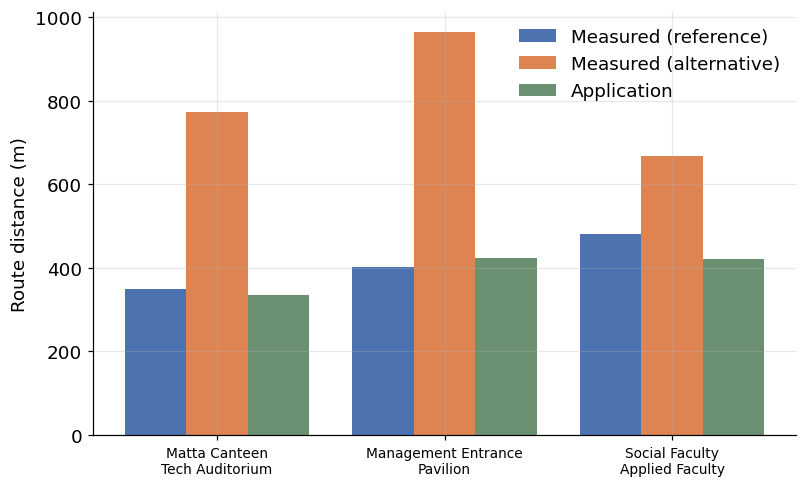

In [56]:
PILOT = pd.DataFrame({
    'journey': ['Matta Canteen -- Tech Auditorium', 'Management Entrance -- Pavilion', 'Social Faculty -- Applied Faculty'],
    'measured_ref_m': [348.90, 401.71, 480.00],
    'measured_alt_m': [771.80, 964.65, 667.30],
    'app_distance_m': [336.0, 423.0, 421.0],
})

if os.path.exists(PHYS_CSV):
    phys = pd.read_csv(PHYS_CSV)
    need = {'journey', 'origin_lat', 'origin_lon', 'dest_lat', 'dest_lon', 'measured_ref_m'}
    assert need <= set(phys.columns), f'{PHYS_CSV} needs columns {need}'
    app_d, snap_o, snap_t, routes_geo = [], [], [], []
    for _, r in phys.iterrows():
        so, do = snap(r.origin_lat, r.origin_lon); st, dt = snap(r.dest_lat, r.dest_lon)
        path, _ = dijkstra_counted(G, so, st)
        app_d.append(path_distance(G, path)); snap_o.append(do); snap_t.append(dt)
        routes_geo.append({'type': 'Feature', 'properties': {'journey': r.journey, 'distance_m': app_d[-1]},
                           'geometry': {'type': 'LineString', 'coordinates': [[n[1], n[0]] for n in path]}})
    phys['app_distance_m'] = app_d; phys['snap_origin_m'] = snap_o; phys['snap_dest_m'] = snap_t
    with open(f'{OUT_DIR}/app_routes.geojson', 'w') as fh:
        json.dump({'type': 'FeatureCollection', 'features': routes_geo}, fh)
    PHYS_SOURCE = 'csv'
else:
    phys = PILOT.copy(); PHYS_SOURCE = 'pilot'
print('Physical comparison source:', PHYS_SOURCE)

phys['error_m']     = phys['app_distance_m'] - phys['measured_ref_m']
phys['error_pct']   = 100 * phys['error_m'] / phys['measured_ref_m']
phys['abs_err_m']   = phys['error_m'].abs()
phys['abs_err_pct'] = phys['error_pct'].abs()
display(phys.round(2))

n_ph = len(phys)
put('RPhysN', n_ph); put('RPhysSource', PHYS_SOURCE)
put('RPhysBias', f2(phys.error_m.mean())); put('RPhysBiasPct', f2(phys.error_pct.mean()))
put('RPhysMAE', f2(phys.abs_err_m.mean())); put('RPhysMAPE', f2(phys.abs_err_pct.mean()))
put('RPhysMaxAbsPct', f2(phys.abs_err_pct.max())); put('RPhysMinAbsPct', f2(phys.abs_err_pct.min()))
put('RPhysOverN', int((phys.error_m > 0).sum())); put('RPhysUnderN', int((phys.error_m < 0).sum()))
if 'measured_alt_m' in phys and phys['measured_alt_m'].notna().all():
    put('RPhysAltRatioMin', f2((phys.measured_alt_m / phys.measured_ref_m).min()))
    put('RPhysAltRatioMax', f2((phys.measured_alt_m / phys.measured_ref_m).max()))
else:
    put('RPhysAltRatioMin', 'n/a'); put('RPhysAltRatioMax', 'n/a')

fig, ax = plt.subplots(figsize=(7.5, 4.6))
x = np.arange(n_ph); wd = 0.27
ax.bar(x - wd, phys.measured_ref_m, wd, label='Measured (reference)', color='#4c72b0')
if 'measured_alt_m' in phys and phys['measured_alt_m'].notna().all():
    ax.bar(x, phys.measured_alt_m, wd, label='Measured (alternative)', color='#dd8452')
ax.bar(x + wd, phys.app_distance_m, wd, label='Application', color=COL['A*'])
ax.set_xticks(x); ax.set_xticklabels([j.replace(' -- ', '\n') for j in phys.journey], fontsize=9)
ax.set_ylabel('Route distance (m)'); ax.legend()
plt.tight_layout(); savefig('fig_physical'); plt.show()